# 01 · Completed data carpentry for a spatial process emulator

**Learning problem:** (deposition recipe, requested substrate x, requested substrate y)
→ **local thickness and conductivity**. Include the planned/calibrated temperature at each location,
not only the library's initial temperature. Each deposition has a set of distinct sampling locations.
We keep one observation per **library + position**, never average a whole substrate into one row,
and never confuse position indices across depositions.

Recipe settings and a requested grid are available before deposition. Measured spectra, composition,
optical summaries, electrical measurements, quality, operator identity, IDs, and focus/stage `xyz_mm`
are not features. Thickness and conductivity are targets only. Bandgap stays in the compact raw
dataset but is not required for this two-output mapping exercise, increasing usable coverage.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
HERE = Path.cwd()
if not (HERE / 'htem_workshop.py').exists():
    HERE = HERE / '03_htem_conductivity'
if not (HERE / 'htem_workshop.py').exists():
    raise FileNotFoundError('Open this notebook from the workshop root or HTEM module folder.')
sys.path.insert(0, str(HERE))
import htem_workshop as htem
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEED = 42

## 1. Examine coverage, units, missingness, and grid integrity

Substrate coordinates come from the API's aligned scalar-map arrays, not an inferred reshape or
post-measurement stage coordinates. Preserve the API's substrate frame and grid orientation; do not
fit a coordinate transformation from measured property values. Unknown XY is excluded from spatial
training, not imputed. A new-process prediction must supply a known requested grid in this same frame.

In [2]:
RAW_FILE = HERE / 'outputs/htem_acquisition/htem_process_raw.parquet'
PREPARED = HERE / 'outputs/htem_prepared'
provenance = json.loads(RAW_FILE.with_suffix('.provenance.json').read_text(encoding='utf-8'))
assert htem.sha256(RAW_FILE) == provenance['sha256']
raw = pd.read_parquet(RAW_FILE)
print(f"{len(raw):,} acquired points, {raw.sample_library_id.nunique():,} libraries; mode={provenance['mode']}")
print('Units: substrate x/y = mm; thickness = um; conductivity = S/cm; optional bandgap = eV.')
display(raw[['x_mm', 'y_mm', *htem.RECIPE_FIELDS, *htem.LABEL_FIELDS]].isna().sum().rename('missing_rows').to_frame())
display(raw[['thickness', 'fpm_conductivity', 'x_mm', 'y_mm']].describe().T)
assert not raw.duplicated(['sample_library_id', 'position']).any()

82,644 acquired points, 1,879 libraries; mode=live_scalar_api
Units: substrate x/y = mm; thickness = um; conductivity = S/cm; optional bandgap = eV.


,missing_rows
x_mm,44
y_mm,44
pdac,0
deposition_sample_time_min,9857
deposition_initial_temp_c,12497
deposition_base_pressure_mtorr,45761
deposition_growth_pressure_mtorr,29437
deposition_compounds,7657
deposition_power,3873
deposition_gases,34497


,count,mean,std,min,25%,50%,75%,max
thickness,54543.0,0.367974,0.444415,0.000000,0.108200,0.234,0.44045,4.997
fpm_conductivity,13676.0,1030.794182,18802.100187,0.000002,0.023102,1.294,48.42250,999700.000
x_mm,82600.0,25.345571,12.714323,-31.640000,13.400000,25.400,37.40000,45.400
y_mm,82600.0,25.334751,14.033973,-31.640000,6.650000,19.150,31.65000,44.150


## 2. Clean and encode without conflating positions

The supplied implementation keeps a position with **either** usable thickness or conductivity.
Thickness outside 0.001–10 µm and nonpositive conductivity become missing labels, not guessed values;
the other valid label can still train its output. Positions with neither label are excluded.
Additional exclusion rules: invalid/missing XY, ambiguous within-library XY, unknown/invalid duration or initial
temperature, or inconsistent powered-target settings. No labels are guessed, clipped, or imputed.
Extreme conductivity is reviewed, not removed simply for being unusual. This is a powered-target
process cohort, not a claim to model every deposition method in the raw inventory.

Preserve source/power and gas/flow slot pairing. Normalize gas/substrate case, not chemical formula
case. Missing active-target power is not zero. Optional missing settings use train-only imputation
with indicators; **spatial coordinates are never imputed**. Substrate XY enters the model; position
and library IDs remain metadata only. Extra pulse/energy/cycle/distance settings are retained in the
raw download, not forced into this sputtering-focused reference feature set.

`absolute_temp_c` becomes `local_temperature_C`, retained independently at every planned grid node,
including nodes without labels. Missing/invalid local temperature remains unknown with a train-fitted
imputation indicator. It is never silently filled from initial temperature. For a new recipe, supply
the planned/calibrated profile in the same substrate frame; the field is not a complete thermal history.

### Source chemistry instead of formula-name one-hot columns

Each target formula supplies atom-fraction-weighted atomic number/mass, Pauling electronegativity
(mean/range/std), atomic radius, first ionization energy, composition entropy, and O/N/S/Se/Te
fractions. Source/power pairing is preserved. We also include independent experimental **reference**
band-gap median/range where the formula is covered. These are **not** measured HTEM film gaps or
certified values for a specific target phase. A formula alone does not identify polymorph, doping,
defects, or measurement temperature. Missing references stay missing with training-only imputation
and explicit known/unknown indicators; no gap is invented or averaged from elemental gaps.

Power-weighted source descriptors are engineered heuristics, **not deposited-film composition**
or a physical mixture band gap. Formula names stay as metadata for recipe identity/material strata,
but are not one-hot encoded. Chamber, substrate, and gas still use train-fitted categories.
Atomic data: [pymatgen v2025.1.9](https://github.com/materialsproject/pymatgen/tree/v2025.1.9).
Band-gap data: [Zhuo et al. (2018)](https://doi.org/10.1021/acs.jpclett.8b00124),
[Expt Gap Data v1](https://doi.org/10.6084/m9.figshare.7289687.v1).
### Electronic DOS references: richer chemistry, without inventing a source phase

Independent [JARVIS electronic DOS](https://doi.org/10.6084/m9.figshare.14745327.v3) supplies
**reference spin-up DOS shapes**, matched by exact normalized source composition. We retain all
matching structures, not an arbitrarily selected polymorph. Each spectrum uses the published 300
samples at 0.05 eV spacing (-5 inclusive, 10 exclusive relative to Fermi); integrals stay within the
sampled -5..9.95 eV support. Unit-area normalization makes these shape features, not absolute DOS.

Per source: spectral centroid/width, occupied-window and near-Fermi (+/-0.5 eV) fractions,
seven coarse energy-bin fractions, reference count, near-Fermi range and mean bin spread across
reference structures. The last two are reference variability, **not calibrated uncertainty**.
Power-weighted centroid/near-Fermi summaries require full active-source coverage; otherwise they
stay missing. Coverage indicators and train-only imputation are explicit. They are not a physical
mixture DOS, deposited composition, carrier density, or predicted film conductivity.

A source formula does not identify its actual atomic coordinates, defects or phase. The instructor
also tested **reference-crystal** embeddings: real JARVIS lattices/species/coordinates passed through
the official frozen ALIGNN formation-energy model, pooled before its scalar prediction head.
All matching reference vectors are averaged and compressed by PCA fit only on unique active
**training** compositions. This is an honest reference-structure proxy, not identification of an
actual HTEM target or film phase. The existing substrate-grid GNN is a different, spatial graph.
No measured HTEM film spectra/structure enter this reference lookup.
Reference: [Kaundinya et al., DOS/ALIGNN (2022)](https://doi.org/10.1007/s11837-022-05199-y).
The compact, checksummed reference summaries ship with the repository; no new packages/API keys
are needed for preparation or training. To reproduce the external download and extraction, run
`uv run --locked python 03_htem_conductivity/htem_source_dos.py` from the repository root.
The 155 MB raw reference archive stays in ignored outputs, not the distributed dataset.

### Instructor-selected frozen features: your experiment changes the model

An instructor-only comparison in `scratch/HTEM_Feature_Selection_Study.ipynb` tested curated
Magpie-style descriptors, pretrained composition vectors, reference-crystal ALIGNN vectors,
and DOS combinations. It used fixed Ridge/Random Forest selectors and the existing grouped
training/validation split. **No test artifact or score was used to select features.**
The lowest mean relative validation RMSE determines `data/htem_feature_selection.json`.
Improvements on one holdout are not proof of universal superiority; the selection record
includes per-selector results and an exploratory whole-group bootstrap interval.

Composition vectors are stoichiometric means of published **16-D MEGNet element vectors**,
not a full Roost/AtomSets network. Curated additions include periodic/valence/radius statistics,
stoichiometry norms and elemental melting-temperature statistics, not a guessed compound melting
point. [MEGNet](https://doi.org/10.1021/acs.chemmater.9b01294),
[ALIGNN](https://doi.org/10.1038/s41524-021-00650-1),
[Magpie](https://doi.org/10.1038/npjcompumats.2016.28).

This notebook loads the **selected** offline source columns and fits imputation/scaling on training
data only. Candidate blocks not selected are not silently added. All five architecture notebooks
read the exact same saved matrices and transforms. No DGL, ALIGNN, external model download,
feature selection, or additional API key is needed during the workshop.

In [3]:
FROZEN_SPLIT = HERE / 'data/frozen_evaluation/paired_split.csv'
clean, audit, manifest = htem.prepare(raw, PREPARED, htem.sha256(RAW_FILE), seed=SEED,
                                     frozen_split=FROZEN_SPLIT)
print('Frozen instructor-selected feature set:', manifest['frozen_feature_selection']['candidate'])
print('Selected optional blocks:', manifest['frozen_feature_selection']['blocks'])
print(f"Retained {len(clean):,} points from {manifest['libraries']} libraries.")
display(audit.loc[audit.excluded, 'reasons'].str.split(';').explode().value_counts().rename('excluded_rows').to_frame())
display(pd.DataFrame({'feature': htem.MODEL_FEATURES,
                      'encoding': ['train-impute optional settings + train-scale; XY always known'] * len(htem.NUMERIC_FEATURES)
                                  + ['train-fitted one-hot'] * len(htem.CATEGORICAL_FEATURES)}))
source_coverage = pd.read_csv(PREPARED / 'source_chemistry_coverage.csv')
display(source_coverage)
print(f"Formula descriptors: {source_coverage.formula_known.sum()}/{len(source_coverage)} source labels; "
      f"independent band-gap reference: {source_coverage.reference_bandgap_eV.notna().sum()}/{len(source_coverage)}.")
print(f"Independent DOS reference: {source_coverage.reference_dos_known.sum()}/{len(source_coverage)} source labels. "
      'Reference phases are not verified source phases; missing coverage stays explicit.')
assert not any(name.startswith('categorical__target_') for name in manifest['encoded_features'])

Frozen instructor-selected feature set: curated_crystal_dos
Selected optional blocks: ['curated', 'crystal', 'dos']
Retained 36,762 points from 859 libraries.


,excluded_rows
reasons,
no_usable_target,26816
no_positive_power,18481
unknown_or_invalid_temperature,12497
unknown_or_invalid_duration,11001
invalid_target_power_pair,5764
missing_grid_position,44
ambiguous_grid_coordinates,44


,feature,encoding
0,duration_min,train-impute optional settings + train-scale; ...
1,initial_temperature_C,train-impute optional settings + train-scale; ...
2,base_pressure_mTorr,train-impute optional settings + train-scale; ...
3,growth_pressure_mTorr,train-impute optional settings + train-scale; ...
4,target_1_power_W,train-impute optional settings + train-scale; ...
...,...,...
266,chamber,train-fitted one-hot
267,substrate,train-fitted one-hot
268,gas_1,train-fitted one-hot
269,gas_2,train-fitted one-hot


,formula,libraries,formula_known,reference_bandgap_eV,bandgap_min_eV,bandgap_max_eV,reference_records,reference_dos_known,reference_dos_records,reference_dos_near_fermi_fraction,reference_dos_mean_bin_std,dos_reference_ids,dos_source,source
0,Ag,15,True,NaN,NaN,NaN,0,True,7,0.024859,0.005007,JVASP-14606;JVASP-16065;JVASP-16261;JVASP-2512...,https://doi.org/10.6084/m9.figshare.14745327.v3,not available
1,Al,1,True,NaN,NaN,NaN,0,True,4,0.143955,0.055408,JVASP-14615;JVASP-25408;JVASP-7148;JVASP-816,https://doi.org/10.6084/m9.figshare.14745327.v3,not available
2,BaS,13,True,3.890,3.88,3.90,2,True,1,0.000024,0.000000,JVASP-1315,https://doi.org/10.6084/m9.figshare.14745327.v3,https://doi.org/10.1021/acs.jpclett.8b00124
3,C,3,True,NaN,NaN,NaN,0,True,47,0.013878,0.047008,JVASP-14740;JVASP-25054;JVASP-25055;JVASP-2507...,https://doi.org/10.6084/m9.figshare.14745327.v3,not available
4,CaS,5,True,5.400,5.38,6.00,3,True,1,0.000012,0.000000,JVASP-1333,https://doi.org/10.6084/m9.figshare.14745327.v3,https://doi.org/10.1021/acs.jpclett.8b00124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,Zn,137,True,NaN,NaN,NaN,0,True,2,0.043305,0.000010,JVASP-1056;JVASP-14820,https://doi.org/10.6084/m9.figshare.14745327.v3,not available
62,ZnO,189,True,3.440,3.20,3.51,22,True,6,0.009739,0.029441,JVASP-1195;JVASP-17188;JVASP-36660;JVASP-36874...,https://doi.org/10.6084/m9.figshare.14745327.v3,https://doi.org/10.1021/acs.jpclett.8b00124
63,ZnS,1,True,3.695,3.54,3.88,20,True,21,0.002309,0.026831,JVASP-10591;JVASP-1702;JVASP-22574;JVASP-22581...,https://doi.org/10.6084/m9.figshare.14745327.v3,https://doi.org/10.1021/acs.jpclett.8b00124
64,ZnSe,15,True,2.800,2.67,2.87,16,True,3,0.000220,0.033347,JVASP-29593;JVASP-8047;JVASP-96,https://doi.org/10.6084/m9.figshare.14745327.v3,https://doi.org/10.1021/acs.jpclett.8b00124


Formula descriptors: 66/66 source labels; independent band-gap reference: 32/66.
Independent DOS reference: 66/66 source labels. Reference phases are not verified source phases; missing coverage stays explicit.


## 2a. Worked feature workflow: the selected representation only

The instructor comparison selected **curated composition descriptors + frozen reference-crystal
ALIGNN embeddings + reference DOS**. MEGNet composition embeddings were tested but are **not**
used here. The combined selector score improved about 2.6% over the earlier DOS enrichment;
the exploratory validation-group interval includes no improvement, so this is not a claim of
statistically established superiority or an optimal representation for every model.

**Expensive extraction, already performed:** download the pinned official ALIGNN formation-energy
checkpoint, build periodic atomic/bond-angle graphs from real JARVIS reference structures,
extract the mean atom representation before the prediction head, and average all exact-composition
references. The function below shows that actual graph-encoding operation. It is defined here but
not rerun during class: its optional ALIGNN/DGL environment and pinned model loader are in
`scratch/build_htem_feature_candidates.py` (see the module README for the exact commands).
The instructor smoke-tests this same function against a cached real structure/vector.

DOS shape reduction/aggregation is implemented in the linked, runnable `htem_source_dos.py`;
the supplied compact summaries avoid shipping full spectra. Neither reference pathway uses
measured HTEM film information. Unknown references remain missing, not guessed.

In [4]:
def encode_reference_crystal(frozen_model, atoms_dictionary):
    """Optional instructor extraction: real periodic graph -> frozen 256-D vector."""
    import torch
    from alignn.graphs import Graph
    from jarvis.core.atoms import Atoms
    atoms = Atoms.from_dict(atoms_dictionary)
    graph, line_graph = Graph.atom_dgl_multigraph(
        atoms, cutoff=8.0, max_neighbors=12, atom_features='cgcnn', compute_line_graph=True)
    captured = []
    hook = frozen_model.fc.register_forward_pre_hook(
        lambda module, args: captured.append(args[0].detach().cpu().numpy().copy()))
    frozen_model.eval()
    frozen_model.requires_grad_(False)
    try:
        with torch.inference_mode():
            frozen_model([graph, line_graph, torch.tensor(atoms.lattice_mat, dtype=torch.float32)])
    finally:
        hook.remove()
    return captured[-1].reshape(-1)  # official mean atom readout before the scalar head

**Run this part in class:** rebuild the selected elemental statistics, fit the crystal PCA using
training-source compositions only, assemble source-slot features, then fit training-only median
imputation and StandardScaler. Transform validation/test without fitting on them. The assertions
below check that the resulting matrices exactly reproduce the instructor's frozen preparation.
No feature comparison or new representation choice happens during this step.

In [5]:
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import htem_chemistry as chemistry

reference = json.loads((HERE / 'data/htem_feature_candidates.json').read_text(encoding='utf-8'))
elemental = json.loads((HERE / 'data/htem_feature_element_reference.json').read_text(encoding='utf-8'))
frozen_source = htem.frozen_features.source_table()
training_recipes = clean[clean.split.eq('train')].drop_duplicates('sample_library_id')
training_keys = sorted({chemistry.composition_key(row[f'target_{i}'])
    for row in training_recipes.to_dict('records') for i in range(1, 4)
    if row[f'target_{i}_power_W'] > 0
    and reference['compositions'][chemistry.composition_key(row[f'target_{i}'])]['crystal_embedding']})
training_vectors = np.array([reference['compositions'][key]['crystal_embedding']['mean'] for key in training_keys])
crystal_pca = PCA(n_components=16, svd_solver='full').fit(training_vectors)
assert training_keys == frozen_source['projection']['training_composition_keys']
np.testing.assert_array_equal(crystal_pca.components_, frozen_source['projection']['components'])

def selected_source_features(formula):
    fields = frozen_source['blocks']['curated'] + frozen_source['blocks']['crystal']
    if formula == '__NONE__':
        return dict.fromkeys(fields, 0.0)  # absent source, not an unknown material
    parsed = chemistry.parse_formula(formula)
    weights = np.array([float(fraction) for element, fraction in parsed])
    values = {'curated_known': 1.0}
    for prop in elemental['property_order']:
        v = np.array([elemental['elements'][element][prop] for element, fraction in parsed], dtype=float)
        values['magpie_mean_' + prop] = float(weights @ v)
        if prop not in ['IsDBlock', 'NsValence', 'NpValence', 'NdValence', 'NfValence', 'NValence']:
            values['magpie_range_' + prop] = float(np.ptp(v))
            values['magpie_std_' + prop] = float(np.sqrt(weights @ (v - weights @ v) ** 2))
    for orbital in 'spdf':
        values['valence_fraction_' + orbital] = values[f'magpie_mean_N{orbital}Valence'] / values['magpie_mean_NValence']
    values['stoichiometry_L2'] = float(np.linalg.norm(weights))
    values['stoichiometry_L3'] = float(np.linalg.norm(weights, ord=3))
    crystal = reference['compositions'].get(chemistry.composition_key(formula), {}).get('crystal_embedding')
    values['crystal_embedding_known'] = float(crystal is not None)
    values['crystal_reference_mean_coordinate_std'] = crystal['mean_coordinate_std'] if crystal else np.nan
    vector = crystal_pca.transform(np.array(crystal['mean']).reshape(1, -1))[0] if crystal else np.full(16, np.nan)
    values.update({f'alignn_pc_{i:02d}': float(value) for i, value in enumerate(vector)})
    return values

worked_inputs = clean[htem.FEATURES].copy()
for slot in range(1, 4):
    lookup = {formula: selected_source_features(formula) for formula in clean[f'target_{slot}'].unique()}
    rebuilt = pd.DataFrame([lookup[formula] for formula in clean[f'target_{slot}']], index=clean.index)
    for feature in rebuilt:
        worked_inputs[f'target_{slot}_{feature}'] = rebuilt[feature].to_numpy()
# Existing recipe/atomic/reference-gap/DOS features remain unchanged; replace
# only the freshly demonstrated curated descriptors and ALIGNN coordinates.
encoder = ColumnTransformer([
    ('numeric', make_pipeline(SimpleImputer(strategy='median', add_indicator=True,
         keep_empty_features=True), StandardScaler()), htem.NUMERIC_FEATURES),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), htem.CATEGORICAL_FEATURES)])
encoder.fit(worked_inputs[clean.split.eq('train')])
for split in htem.SPLITS:
    reproduced = encoder.transform(worked_inputs[clean.split.eq(split)]).astype('float32')
    np.testing.assert_array_equal(reproduced, data[split]['X'] if 'data' in globals()
                                  else np.load(PREPARED / f'{split}.npz', allow_pickle=False)['X'])
print(f'Rebuilt {len(training_keys)} training-source reference embeddings -> 16 crystal coordinates per source.')
print('Curated statistics + reference crystal PCA + existing DOS/recipe inputs exactly reproduce all three frozen matrices.')
print('All architecture notebooks consume those matrices unchanged; your task is to experiment with the model.')

Rebuilt 65 training-source reference embeddings -> 16 crystal coordinates per source.
Curated statistics + reference crystal PCA + existing DOS/recipe inputs exactly reproduce all three frozen matrices.
All architecture notebooks consume those matrices unchanged; your task is to experiment with the model.


## 3. Balance material classes while keeping whole depositions together

All grid locations of a library stay in one split. Libraries with identical recipe vectors also
stay together, **even when sampled on different grids**. Otherwise the model could memorize one
deposition and appear to predict an unseen nearby position.

Stratify by the **combination of active target materials** (positive-power sources), independent
of their ordering. This is a recipe category, not measured film composition. Source slots and
source/power pairing remain unchanged in the actual model inputs. Aim for 60/20/20 independent
groups **within each material class**; do not duplicate maps or force equally frequent classes.
Every class with at least three independent groups appears in train, validation, and test.
A one-group class stays in training; a two-group class gets training plus one holdout. Those
classes cannot be represented in all three splits without leakage. Integer quotas and unequal
grid sizes mean overall group/point fractions will differ from 60/20/20.

The balance table reports independent groups, libraries, and points separately. The splitter
uses categories and group sizes, never property values or model performance. Recipe identity uses
original process settings/formulas, not derived chemical descriptors: adding descriptors leaves
the established material-balanced assignments unchanged. Rerun all models after preparation changes.
Test remains for final reporting after validation selection.

**Expanding without moving the old holdouts:** `data/frozen_evaluation/paired_split.csv` freezes the
original observations and all original library assignments. New connected groups fill material-class
split deficits without moving any original library. New positions on old libraries inherit their split.
Metrics on the expanded holdouts and on the **original paired test points** are reported separately;
they are not interchangeable. Archived old runs are retained locally for before/after inspection.

Both targets use log10 followed by independent training-only standardization. Input scaling,
imputation, categorical vocabularies, and target transforms use training data only. IDs, position,
and original XY are retained beside arrays so every prediction returns to the correct map point.

In [6]:
data, transforms, manifest = htem.load_prepared(PREPARED)
display(clean.groupby('split').agg(points=('id', 'size'), libraries=('sample_library_id', 'nunique'),
                                  recipe_groups=('leakage_group', 'nunique')).reindex(['train', 'validation', 'test']))
balance = pd.read_csv(PREPARED / 'material_split_balance.csv')
display(balance[['material_class', 'total_groups', 'train_groups', 'validation_groups', 'test_groups', 'coverage_note']])
summary = manifest['material_stratification']
print(f"{summary['classes_present_in_all_splits']}/{summary['material_classes']} material classes occur in every split.")
print(f"Rare exceptions: {summary['singleton_classes_train_only']} singleton classes; "
      f"{summary['two_group_classes_train_plus_one_holdout']} two-group classes. See the saved balance CSV.")
assert balance.loc[balance.all_splits_feasible, 'all_splits_present'].all()
assert balance.train_groups.gt(0).all()
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    a, b = clean[clean.split.eq(left)], clean[clean.split.eq(right)]
    assert set(a.sample_library_id).isdisjoint(b.sample_library_id)
    assert set(a.leakage_group).isdisjoint(b.leakage_group)
display(pd.DataFrame(manifest['label_counts']).T.rename_axis('split'))
print(f"Finite uniform inputs: {data['train']['X'].shape[1]} features → 2 targets with explicit observed-label masks.")
print('Original paired evaluation counts:', manifest['frozen_evaluation']['counts'])
print('Frozen full raw substrate grids saved separately, BEFORE target filtering.')

,points,libraries,recipe_groups
split,,,
train,22272,520,494
validation,7127,166,162
test,7363,173,165


,material_class,total_groups,train_groups,validation_groups,test_groups,coverage_note
0,CoO + NiO + ZnO,53,32,11,10,all splits
1,Sn + Zn,38,23,8,7,all splits
2,Co + Sn + Ta,27,16,5,6,all splits
3,N2 + Sn + Zn,27,16,5,6,all splits
4,CoO + NiO,26,16,5,5,all splits
...,...,...,...,...,...,...
119,SnSe2,1,1,0,0,train only; one independent group
120,SrS,1,1,0,0,train only; one independent group
121,V,1,1,0,0,train only; one independent group
122,W + Zn,1,1,0,0,train only; one independent group


70/124 material classes occur in every split.
Rare exceptions: 37 singleton classes; 17 two-group classes. See the saved balance CSV.


,log10_thickness_um,log10_conductivity_S_cm
split,,
train,21360,6377
validation,6776,2260
test,7182,2289


Finite uniform inputs: 361 features → 2 targets with explicit observed-label masks.
Original paired evaluation counts: {'train': 5465, 'test': 2108, 'validation': 1909}
Frozen full raw substrate grids saved separately, BEFORE target filtering.


## 4. Examine anomalies using training-only references

Statistical flags are prompts for inspection, not automatic deletion. Missing-data selection and
sparse chemistry still limit generalization. Notebook 02 changes models, not this prepared cohort.

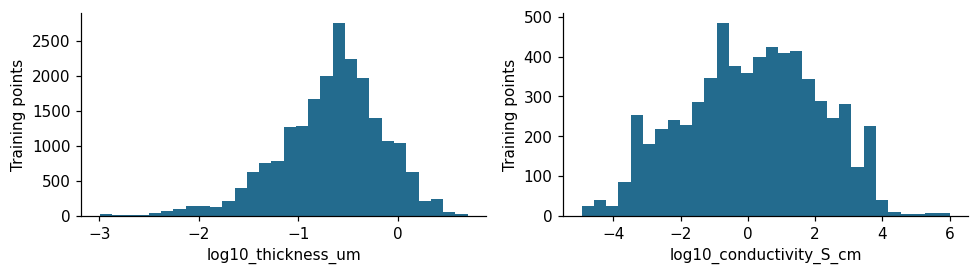

,target,IQR_review_flags,action
0,log10_thickness_um,551,retain; not proven wrong
1,log10_conductivity_S_cm,1,retain; not proven wrong


,feature,categories,categories_in_only_one_library
0,chamber,4,0
1,substrate,22,8
2,gas_1,6,0
3,gas_2,7,1
4,gas_3,4,0


In [7]:
training = clean[clean.split.eq('train')]
fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
flags = []
for ax, target in zip(axes, htem.TARGETS):
    values = training[target].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    unusual = ~values.between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
    flags.append({'target': target, 'IQR_review_flags': int(unusual.sum()), 'action': 'retain; not proven wrong'})
    ax.hist(values, bins=30, color='#236b8e')
    ax.set(xlabel=target, ylabel='Training points')
fig.tight_layout()
fig.savefig(PREPARED / 'training_target_distributions.png', bbox_inches='tight')
plt.show()
display(pd.DataFrame(flags))
display(pd.DataFrame([{'feature': c, 'categories': training[c].nunique(),
                       'categories_in_only_one_library': int((training.groupby(c).sample_library_id.nunique() == 1).sum())}
                      for c in htem.CATEGORICAL_FEATURES]))